# La proximité entre toutes les stations : 

In [4]:
from pathlib import Path

import numpy as np
import pandas as pd

CSV_PATH = Path("historique_merged.csv")

COLONNES = [
    "horodatage", "station_code", "capacity", "velo_meca", "velo_elec",
    "station_name", "coordonnees", "operative",
]

In [6]:
df = pd.read_csv(CSV_PATH, header=None, names=COLONNES)
df["horodatage"] = pd.to_datetime(df["horodatage"], utc=True)
df[["latitude", "longitude"]] = df["coordonnees"].str.split(",", expand=True).astype(float)
df = df.drop(columns="coordonnees")

dans_paris = df["latitude"].between(48.815, 48.902) & df["longitude"].between(2.224, 2.470)
df = df[dans_paris].copy()
df = df[df["capacity"] > 0].copy()

df["available"] = df["velo_meca"] + df["velo_elec"]
print(df.shape)

(3004147, 10)


In [ ]:
# Les Fonctions
RAYON_TERRE_M = 6_371_000
RAYON_VOISINAGE_M = 300


def table_stations(df: pd.DataFrame) -> pd.DataFrame:
    # Renvoie une ligne par station avec ses coordonnées.
    return (
        df.groupby("station_code")[["latitude", "longitude"]]
        .first()
        .reset_index()
    )


def matrice_distances_m(latitudes: np.ndarray, longitudes: np.ndarray) -> np.ndarray:
    # Distance en mètres entre chaque paire de points (formule de haversine).
    lat = np.radians(latitudes)
    lon = np.radians(longitudes)
    d_lat = lat[:, None] - lat[None, :]
    d_lon = lon[:, None] - lon[None, :]
    a = (
        np.sin(d_lat / 2) ** 2
        + np.cos(lat[:, None]) * np.cos(lat[None, :]) * np.sin(d_lon / 2) ** 2
    )
    return 2 * RAYON_TERRE_M * np.arcsin(np.sqrt(a))


def stations_voisines(stations: pd.DataFrame, rayon_m: float = RAYON_VOISINAGE_M) -> pd.DataFrame:
    # Renvoie les paires de stations voisines 
    dist = matrice_distances_m(
        stations["latitude"].to_numpy(), stations["longitude"].to_numpy()
    )
    np.fill_diagonal(dist, np.inf)  # une station n'est pas sa propre voisine
    i, j = np.where(dist <= rayon_m)
    codes = stations["station_code"].to_numpy()
    return pd.DataFrame(
        {"station_code": codes[i], "voisin_code": codes[j], "distance_m": dist[i, j].round(1)}
    )

In [ ]:
# Utilisation
stations = table_stations(df)
paires = stations_voisines(stations, rayon_m=300)

stations["nb_voisins"] = (
    stations["station_code"].map(paires["station_code"].value_counts()).fillna(0).astype(int)
)

print(f"{len(paires):,} paires de voisines")
print(stations["nb_voisins"].describe())
print((stations["nb_voisins"] == 0).sum(), "stations sans voisine")

2,818 paires de voisines
count    1215.000000
mean        2.319342
std         1.833717
min         0.000000
25%         1.000000
50%         2.000000
75%         3.000000
max         9.000000
Name: nb_voisins, dtype: float64
209 stations sans voisine


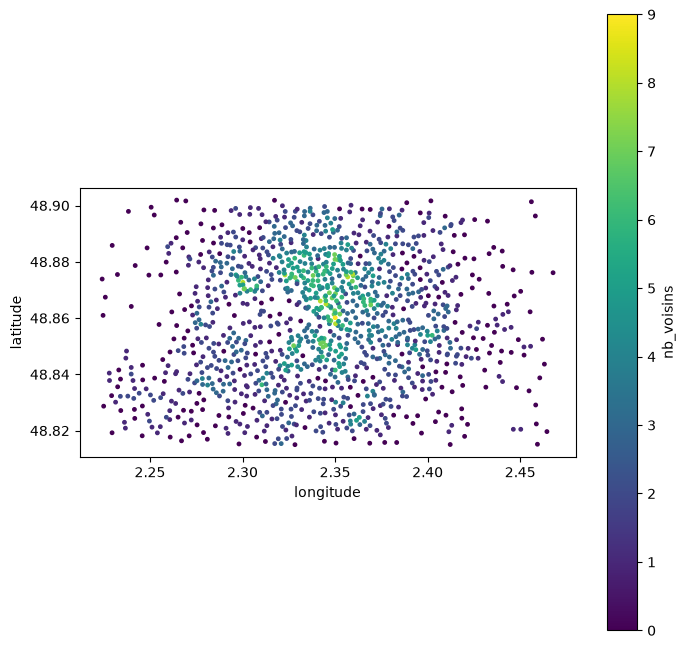

In [ ]:
# Voir le résultat sur une carte
ax = stations.plot.scatter(
    x="longitude", y="latitude", c="nb_voisins", cmap="viridis", s=6, figsize=(8, 8)
)
ax.set_aspect(1 / np.cos(np.radians(48.86)))

In [ ]:
# Ajout du nom de la station et le nom du voisin pour rendre la table lisible
paires_lisibles = paires.merge(
    df[['station_code', 'station_name']].drop_duplicates(), 
    on='station_code', 
    how='left'
).merge(
    df[['station_code', 'station_name']].drop_duplicates(), 
    left_on='voisin_code', 
    right_on='station_code', 
    suffixes=('', '_voisin'),
    how='left'
)[['station_name', 'station_name_voisin', 'distance_m']]

# Afficher les 10 premières paires avec de vrais noms
print(paires_lisibles.head(10))

                    station_name                    station_name_voisin  \
0  Quai de l'Horloge - Pont Neuf                Pont de Lodi - Dauphine   
1   Victoria - Place du Chatelet                   Saint-Denis - Rivoli   
2   Victoria - Place du Chatelet                   Halles - Bourdonnais   
3   Victoria - Place du Chatelet  Lavandieres Sainte Opportune - Rivoli   
4   Victoria - Place du Chatelet                     Saint-Bon - Rivoli   
5           Saint-Denis - Rivoli           Victoria - Place du Chatelet   
6           Saint-Denis - Rivoli                   Halles - Bourdonnais   
7           Saint-Denis - Rivoli                     Pont Neuf - Rivoli   
8           Saint-Denis - Rivoli               Cossonnerie - Sébastopol   
9           Saint-Denis - Rivoli  Lavandieres Sainte Opportune - Rivoli   

   distance_m  
0       237.9  
1       131.6  
2       281.4  
3       145.1  
4       241.4  
5       131.6  
6       197.0  
7       289.2  
8       282.4  
9        82.0 

In [13]:
print(f"{len(paires):,} paires, {stations['station_code'].nunique()} stations")
print(stations["nb_voisins"].describe())
print((stations["nb_voisins"] == 0).sum(), "stations sans voisine")

2,818 paires, 1215 stations
count    1215.000000
mean        2.319342
std         1.833717
min         0.000000
25%         1.000000
50%         2.000000
75%         3.000000
max         9.000000
Name: nb_voisins, dtype: float64
209 stations sans voisine


In [ ]:
# Vérification que les paires sont symétriques 
couples = set(zip(paires["station_code"], paires["voisin_code"]))
asymetriques = [(a, b) for a, b in couples if (b, a) not in couples]
print(len(asymetriques), "paires non symétriques")  # doit afficher 0

0 paires non symétriques


In [ ]:
# Code pour choisir le rayon de voisinage le plus pertinent
dist = matrice_distances_m(
    stations["latitude"].to_numpy(), stations["longitude"].to_numpy()
)
np.fill_diagonal(dist, np.inf)

plus_proche = pd.Series(dist.min(axis=1))
print(plus_proche.describe(percentiles=[0.5, 0.8, 0.9, 0.95, 0.99]))

VITESSE_MARCHE_M_MIN = 80  # environ 5 km/h

for rayon in (300, 400, 500, 600, 800):
    nb = (dist <= rayon).sum(axis=1)
    print(
        f"{rayon} m (~{rayon / VITESSE_MARCHE_M_MIN:.0f} min à pied) : "
        f"médiane {np.median(nb):.0f} voisines, {(nb == 0).mean():.1%} sans voisine"
    )

count    1215.000000
mean      224.090074
std       114.954058
min        19.253723
50%       203.524083
80%       288.787002
90%       345.530266
95%       432.158210
99%       630.054492
max      1168.230980
dtype: float64
300 m (~4 min à pied) : médiane 2 voisines, 17.2% sans voisine
400 m (~5 min à pied) : médiane 5 voisines, 6.0% sans voisine
500 m (~6 min à pied) : médiane 8 voisines, 3.1% sans voisine
600 m (~8 min à pied) : médiane 11 voisines, 1.4% sans voisine
800 m (~10 min à pied) : médiane 20 voisines, 0.5% sans voisine


In [16]:
# Application du rayon de 500m
RAYON_VOISINAGE_M = 500

paires = stations_voisines(stations, rayon_m=RAYON_VOISINAGE_M)
stations["nb_voisins"] = (
    stations["station_code"].map(paires["station_code"].value_counts()).fillna(0).astype(int)
)

isolees = stations[stations["nb_voisins"] == 0]
print(f"{len(paires):,} paires, {len(isolees)} stations isolées")
print(stations["nb_voisins"].describe())

9,628 paires, 38 stations isolées
count    1215.000000
mean        7.924280
std         4.593799
min         0.000000
25%         5.000000
50%         8.000000
75%        10.000000
max        22.000000
Name: nb_voisins, dtype: float64


In [ ]:
## Endroits importants à proximité des stations 


In [30]:
# 1. Convertir l'horodatage et isoler le jour de la semaine (5 = samedi)
df['horodatage'] = pd.to_datetime(df['horodatage'])
df['date_str'] = df['horodatage'].dt.strftime('%Y-%m-%d')
df['heure'] = df['horodatage'].dt.hour

# 2. Filtrer uniquement tous les samedis
df_samedis = df[df['horodatage'].dt.dayofweek == 5].copy()

# 3. Séparer samedis de manif et samedis témoins
dates_manif = ['2026-10-17', '2026-10-24']

df_manif = df_samedis[df_samedis['date_str'].isin(dates_manif)]
df_normal = df_samedis[~df_samedis['date_str'].isin(dates_manif)]

# 4. Calculer la disponibilité moyenne par heure pour chaque groupe
profil_manif_17 = df_manif[df_manif['date_str'] == '2026-10-17'].groupby('heure')['available'].mean()
profil_manif_24 = df_manif[df_manif['date_str'] == '2026-10-24'].groupby('heure')['available'].mean()
profil_normal_moyen = df_normal.groupby('heure')['available'].mean()

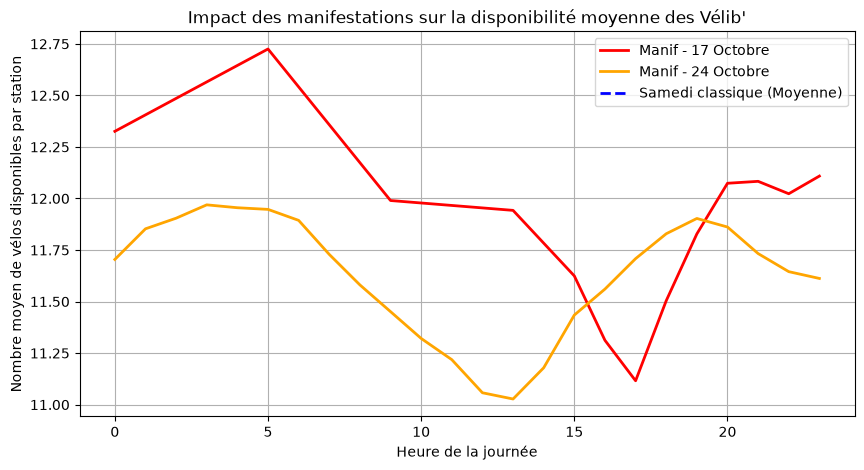

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

# Samedis de manifestation
plt.plot(profil_manif_17.index, profil_manif_17.values, label="Manif - 17 Octobre", color="red", linewidth=2)
plt.plot(profil_manif_24.index, profil_manif_24.values, label="Manif - 24 Octobre", color="orange", linewidth=2)

# Référence (Samedi normal)
plt.plot(profil_normal_moyen.index, profil_normal_moyen.values, label="Samedi classique (Moyenne)", color="blue", linestyle="--", linewidth=2)

plt.title("Impact des manifestations sur la disponibilité moyenne des Vélib'")
plt.xlabel("Heure de la journée")
plt.ylabel("Nombre moyen de vélos disponibles par station")
plt.legend()
plt.grid(True)
plt.show()

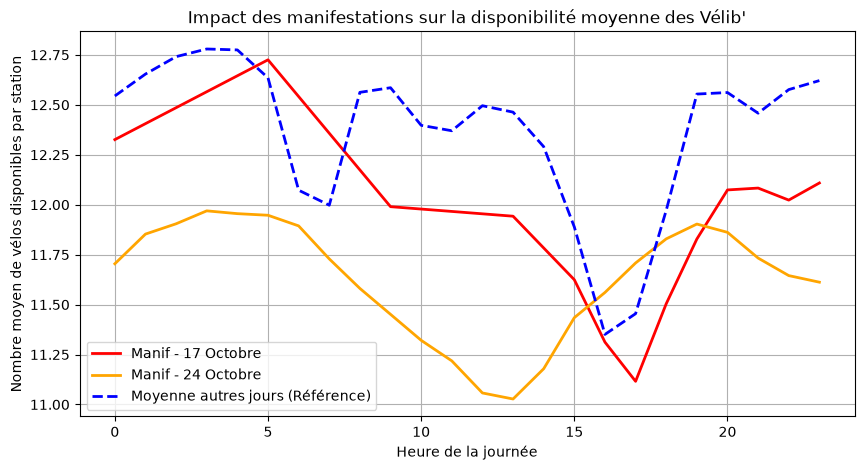

In [32]:
# 1. Isoler les samedis de manif et tous les autres jours
dates_manif = ['2026-10-17', '2026-10-24']

profil_manif_17 = df[df['date_str'] == '2026-10-17'].groupby('heure')['available'].mean()
profil_manif_24 = df[df['date_str'] == '2026-10-24'].groupby('heure')['available'].mean()

# Référence : moyenne horaire de TOUS les autres jours du dataset
profil_autres_jours = df[~df['date_str'].isin(dates_manif)].groupby('heure')['available'].mean()

# 2. Tracer le graphique avec la référence
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(profil_manif_17.index, profil_manif_17.values, label="Manif - 17 Octobre", color="red", linewidth=2)
plt.plot(profil_manif_24.index, profil_manif_24.values, label="Manif - 24 Octobre", color="orange", linewidth=2)
plt.plot(profil_autres_jours.index, profil_autres_jours.values, label="Moyenne autres jours (Référence)", color="blue", linestyle="--", linewidth=2)

plt.title("Impact des manifestations sur la disponibilité moyenne des Vélib'")
plt.xlabel("Heure de la journée")
plt.ylabel("Nombre moyen de vélos disponibles par station")
plt.legend()
plt.grid(True)
plt.show()

In [33]:
df['is_manifestation'] = df['date_str'].isin(['2026-10-17', '2026-10-24']).astype(int)